# 02 - Price analysis (EDA)

Checks the price data before modelling: distribution of price and area, size of each property type and province, and price per m² by property type.

**Research objectives**

Purpose: check the price data before modelling and decide how to prepare the target and the features.

1. **Target:** How are `price` and `price_per_m2` distributed, and is a log transform needed?
2. **Categories:** Do property types and provinces have enough listings to be used as features?

Assumption: every listing is treated as a property for sale, and `price` is the price the seller asks for. Some rent listings may remain. Results only cover listings that show a price.


## 0. SET UP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12

In [2]:
df_priced = pd.read_parquet("../data/processed/priced_listings.parquet")
df_priced["price_per_m2"] = df_priced["price"] / df_priced["area"]

numeric_cols = [
    "price", "area", "floor_count", "frontage_width", "house_depth",
    "road_width", "bedroom_count", "bathroom_count",
]
print("df_priced:", df_priced.shape)

df_priced: (2412798, 20)


## 2. EXPLORATORY DATA ANALYSIS

All figures use `df_priced` (positive price and area, duplicates removed, price within range).


### 2.1. General dataset profile


In [3]:
display(df_priced[numeric_cols].describe())

,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count
count,2.412798e+06,2.412798e+06,517454.000000,1.217495e+06,59040.000000,416300.000000,1.312102e+06,1.228546e+06
mean,1.502312e+10,4.160076e+02,3.898350,2.338081e+01,23.841507,9.537925,3.313252e+00,3.058710e+00
std,3.285986e+10,9.226919e+04,1.813252,1.039143e+04,97.324889,47.688168,2.591904e+00,2.552136e+00
min,1.000000e+08,1.200000e+00,1.000000,5.000000e-01,1.000000,0.500000,1.000000e+00,1.000000e+00
25%,4.050000e+09,5.600000e+01,3.000000,4.200000e+00,13.400000,4.000000,2.000000e+00,2.000000e+00
50%,7.400000e+09,8.000000e+01,4.000000,5.000000e+00,18.750000,6.000000,3.000000e+00,2.000000e+00
75%,1.430000e+10,1.200000e+02,5.000000,7.600000e+00,24.750000,10.500000,4.000000e+00,4.000000e+00
max,1.000000e+12,8.200000e+07,255.000000,9.080000e+06,15380.000000,18000.000000,2.000000e+02,1.680000e+02


### 2.2. Price distributions


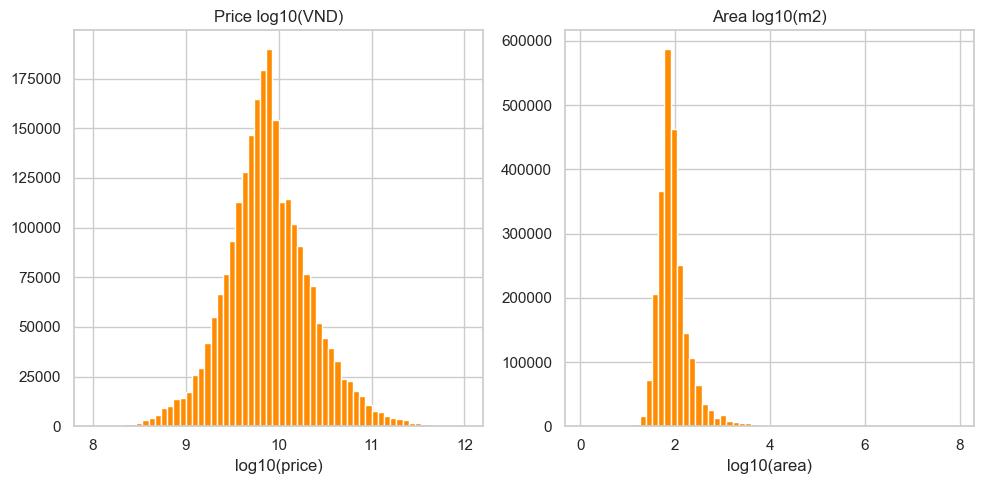

In [4]:
fig, axes = plt.subplots(1, 2)
for ax, col, title in [
    (axes[0], "price", "Price log10(VND)"),
    (axes[1], "area", "Area log10(m2)"),
]:
    ax.hist(np.log10(df_priced[col]), bins=60, color="darkorange")
    ax.set_title(title)
    ax.set_xlabel(f"log10({col})")

plt.tight_layout()
plt.show()

### 2.3. Group coverage

How many listings each property type and province has. Groups with fewer than 100 listings are hard to use as features.

In [5]:
for col in ["property_type_name", "province_name"]:
    counts = df_priced[col].value_counts(dropna=False)
    print(f"{col}: {len(counts)} groups, {int((counts >= 100).sum())} with n >= 100")
    display(counts.head(15).to_frame("n"))

property_type_name: 5 groups, 5 with n >= 100


,n
property_type_name,
Nhà,1080119
Đất,565074
Căn hộ chung cư,547956
Biệt thự/Nhà liền kề,180047
Shophouse,39602


province_name: 63 groups, 60 with n >= 100


,n
province_name,
Hồ Chí Minh,933078
Hà Nội,782054
Đà Nẵng,125260
Bình Dương,104507
Khánh Hòa,70070
Hải Phòng,50031
Hưng Yên,45602
Đồng Nai,40502
Bà Rịa - Vũng Tàu,35254


### 2.4. Area–price relationships


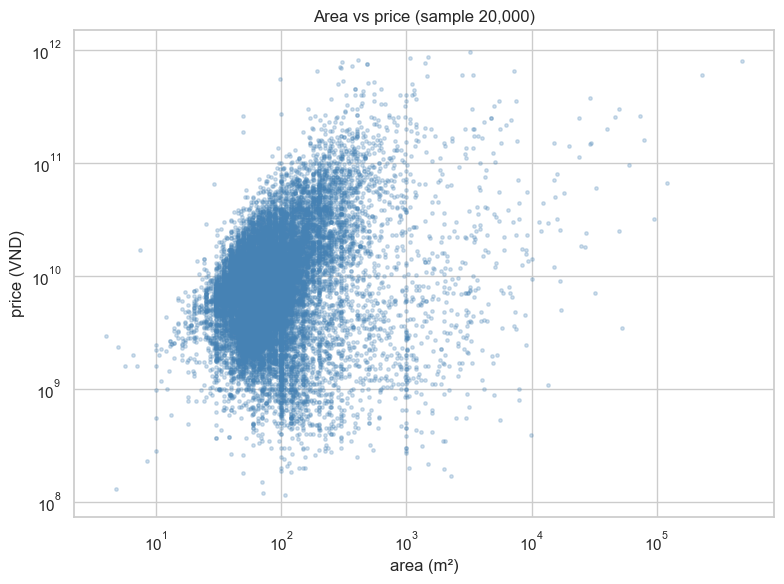

In [6]:
scatter_n = min(20_000, len(df_priced))
scatter_df = df_priced.sample(n=scatter_n, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scatter_df["area"], scatter_df["price"], s=6, alpha=0.25, c="steelblue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("area (m²)")
ax.set_ylabel("price (VND)")
ax.set_title(f"Area vs price (sample {scatter_n:,})")
plt.tight_layout()
plt.show()

### 2.5. Price per square meter by property type

A property type whose histogram has two peaks may mix different kinds of listing (for example sale and rent).


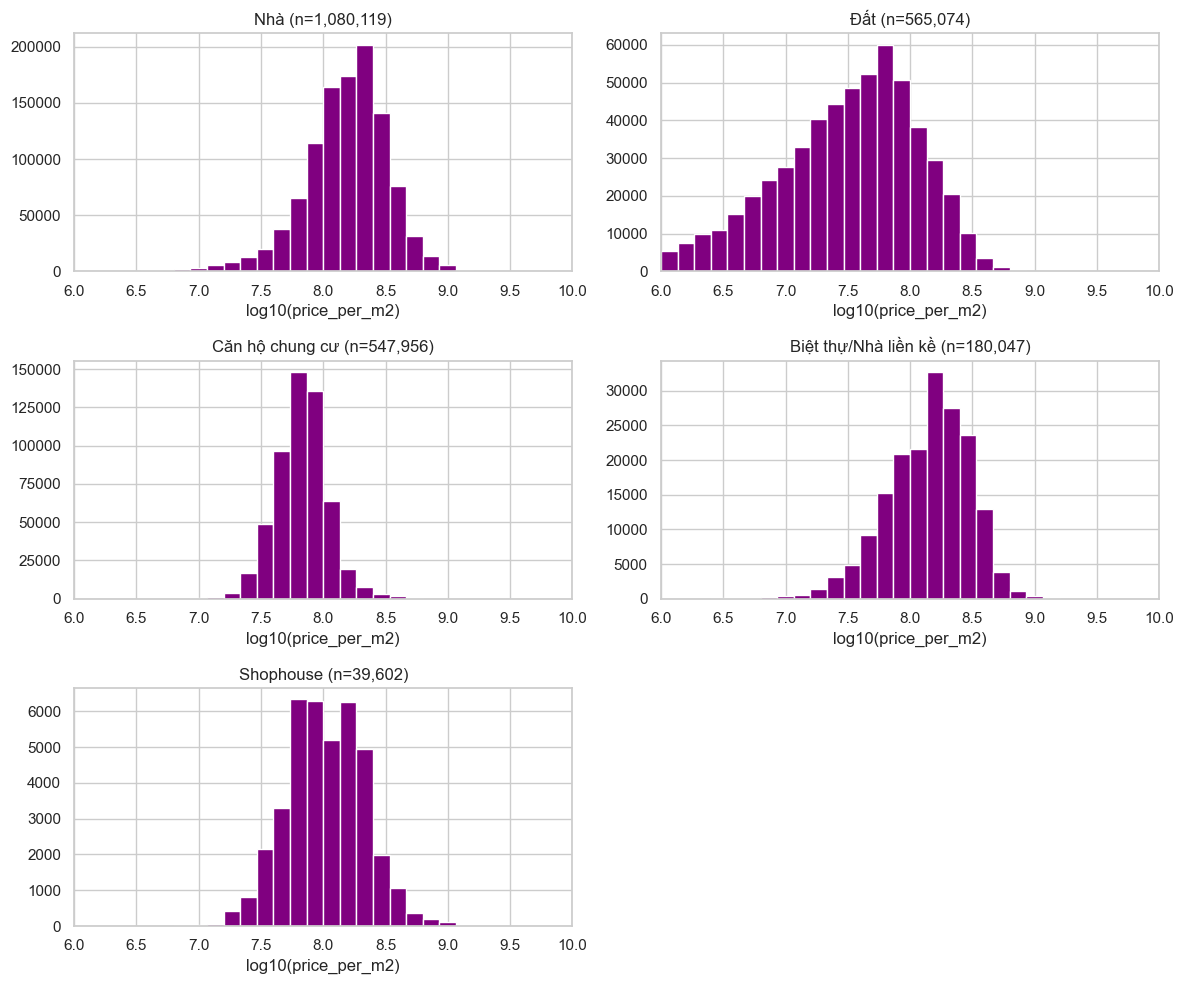

In [7]:
top_types = df_priced["property_type_name"].value_counts().head(5).index

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.ravel()
for ax, t in zip(axes, top_types):
    vals = np.log10(df_priced.loc[df_priced["property_type_name"] == t, "price_per_m2"])
    ax.hist(vals, bins=30, range=(6, 10), color="purple")
    ax.set_xlim(6, 10)
    ax.set_title(f"{t} (n={len(vals):,})")
    ax.set_xlabel("log10(price_per_m2)")
axes[5].set_visible(False)
plt.tight_layout()
plt.show()